# Adversarial Search: Playing Connect 4

Student Name: [Add your name]

I have used the following AI tools: [list tools]

I understand that my submission needs to be my own work: [your initials]

## Learning Outcomes

* Implement adversarial search algorithms for strategic game play.
* Analyze and optimize search in complex game spaces.
* Design effective heuristic evaluation functions.
* Compare performance across different agent strategies.
* Evaluate algorithmic trade-offs between decision quality and efficiency.

## Instructions

Total Points: Undergraduates 100, graduate students 110

Complete this notebook and submit it. The notebook needs to be a complete project report with your implementation, documentation including a short discussion of how your implementation works and your design choices, and experimental results (e.g., tables and charts with simulation results) with a short discussion of what they mean. Use the provided notebook cells and insert additional code and markdown cells as needed. Submit the completely rendered notebook as a HTML file. 


## Introduction

You will implement different versions of agents that play Connect 4:

> "Connect 4 is a two-player connection board game, in which the players choose a color and then take turns dropping colored discs into a seven-column, six-row vertically suspended grid. The pieces fall straight down, occupying the lowest available space within the column. The objective of the game is to be the first to form a horizontal, vertical, or diagonal line of four of one's own discs." (see [Connect Four on Wikipedia](https://en.wikipedia.org/wiki/Connect_Four))

Note that [Connect-4 has been solved](https://en.wikipedia.org/wiki/Connect_Four#Mathematical_solution)
in 1988. A connect-4 solver with a discussion of how to solve different parts of the problem can be found here: https://connect4.gamesolver.org/en/

In [1]:
# change directory to Google Drive for Google Colab
try:
    from google.colab import drive
    import os

    drive.mount('/content/drive')
    os.chdir('/content/drive/My Drive/Colab Notebooks/')
    print("Your working directory is now Google Drive: My Drive > Colab Notebooks")
except ImportError:
    pass

## Task 1: Defining the Search Problem [10 point]

**State.** A state is the board (a two-dimensional NumPy integer array) together with the player whose turn it is. Cells are `0` (empty), `1` (player 1), or `-1` (player -1). The initial state is an empty 6-by-7 board with player 1 to move. The board alone does not encode whose turn it is; search code keeps that player separately.

**Actions.** `actions(state)` returns the column indices whose top cells are empty. These are exactly the columns into which another disc can legally fall; terminal states have no actions.

**Transition model.** `result(state, player, action)` copies the board, places `player` in the lowest empty row of `action`, and returns the new board. It never mutates the input. The caller changes the side to move after each transition.

**Terminal test and utility.** `terminal(state)` is true when either player has four consecutive discs horizontally, vertically, or diagonally, or when the board is full. `utility(state, player)` returns `+1` for a win by `player`, `-1` for the opponent's win, and `0` for a draw. It returns `None` for a non-terminal state because no terminal payoff has been determined yet.

The notebook first calls this a ?character array?, but then specifies players as `1` and `-1`, and its starter code creates numeric zeroes. This implementation follows the explicit numeric player encoding and starter code, using an integer NumPy array so the search modules can compare player values directly.

In [2]:
from connect4_core import actions, empty_board, result, terminal, utility

How big is the state space? Give an estimate and explain it.

For the standard board there are 42 cells, so ignoring gravity and turn order gives the loose bound `3^42 ? 1.09 ? 10^20` assignments. A more informative upper bound counts only stacked columns (each column has height 0 through 6) and positions whose counts are consistent with player 1 moving first. Let `a_k` be the coefficient of `x^k` in `(1 + x + x^2 + ... + x^6)^7`. Then the number of such layouts is at most

`sum(k=0..42) a_k * C(k, ceil(k/2)) ? 7.07 ? 10^13`.

This is still an upper bound: it includes boards that cannot occur because the game would already have ended on an earlier move. The exact reachable state count is smaller. A state also includes the side to move, which is determined by the number of discs for non-terminal states.

How big is the game tree that minimax search will go through? Give an estimate and explain it.

A game has at most 42 moves and at most 7 choices at any move. Thus a deliberately loose upper bound for a full-width minimax tree is

`1 + 7 + 7^2 + ... + 7^42 = (7^43 - 1) / 6 ? 3.64 ? 10^35` nodes.

This bound acts as if all seven columns remain available at every depth and ignores wins, so the real tree is smaller. It is nevertheless enormous. Unlike the state space, a game tree counts paths: the same board may be reached by playing independent columns in a different order, so it can appear in multiple tree nodes. Terminal detection and alpha-beta pruning reduce the work, but exhaustive minimax on the standard board is not practical.

## Task 2: Game Environment and Random Agent [25 point]

Use a numpy character array as the board.

In [3]:
import numpy as np
from connect4_core import empty_board

print(empty_board())

[[0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]]


The standard board is $6 \times 7$ but you can use smaller boards to test your code. Instead of colors (red and yellow), I use 1 and -1 to represent the players. Make sure that your agent functions all have the from: `agent_type(board, player = 1)`, where board is the current board position (in the format above) and player is the player whose next move it is and who the agent should play (as 1 and -1).

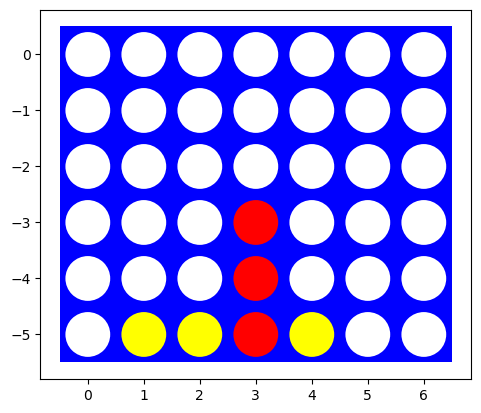

In [4]:
# Visualization code by Randolph Rankin

import matplotlib.pyplot as plt

def visualize(board):
    plt.axes()
    rectangle=plt.Rectangle((-0.5,len(board)*-1+0.5),len(board[0]),len(board),fc='blue')
    circles=[]
    for i,row in enumerate(board):
        for j,val in enumerate(row):
            color='white' if val==0 else 'red' if val==1 else 'yellow'
            circles.append(plt.Circle((j,i*-1),0.4,fc=color))

    plt.gca().add_patch(rectangle)
    for circle in circles:
        plt.gca().add_patch(circle)

    plt.axis('scaled')
    plt.show()
    
board = [[0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 1, 0, 0, 0],
         [0, 0, 0, 1, 0, 0, 0],
         [0,-1,-1, 1,-1, 0, 0]]
visualize(board)

Implement helper functions for:

* A check for available actions in each state `actions(state)`.
* The transition model `result(state, player, action)`.
* Check for terminal states `terminal(state)`.
* The utility function `utility(state, player)`.

The player argument is used so your agent can play red or yellow. Make sure that all these functions work with boards of different sizes (number of columns and rows). You can follow the [tic-tac-toe example from class](tictactoe_definitions.ipynb).

**Input and error behavior:** boards must be non-empty, two-dimensional NumPy integer arrays containing only `-1`, `0`, and `1`; `player` must be `1` or `-1`; and `action` must be an in-range integer column. Invalid boards/players/actions raise `TypeError` or `ValueError`. A move on a full column or terminal board raises `ValueError`. The input board is not changed. `actions` returns an empty list in terminal states; `utility` returns `None` while play is ongoing and raises `ValueError` if an invalid board shows winning lines for both players.

Keep `connect4_core.py` in the same directory as this notebook so the imports work in Jupyter.

In [5]:
from connect4_core import actions, result, terminal, utility

Implement an agent that plays randomly. Make sure the agent function receives as the percept the board and returns a valid action. Use an agent function definition with the following signature (arguments):

`def random_player(board, player = 1): ...`

The argument `player` is used for agents that do not store what color they are playing. The value passed on by the environment should be 1 ot -1 for player red and yellow, respectively.  See [Experiments section for tic-tac-toe](tictactoe_and_or_tree_search.ipynb#Experiments) for an example.

In [6]:
from connect4_core import random_player

Let two random agents play 1,000 games. The experiment below alternates which player moves first (500 games each) to balance the first-move position. It reports wins by board player (`1` or `-1`), not by the function name, because both agents use the same policy. Each game is checked to have reached a terminal state.

In [7]:
from collections import Counter

number_of_games = 1000
np.random.seed(20261108)
results = Counter({1: 0, -1: 0, 0: 0})
first_moves = Counter({1: 0, -1: 0})
first_player_wins = 0

for game_index in range(number_of_games):
    board = empty_board()
    first_player = 1 if game_index % 2 == 0 else -1
    first_moves[first_player] += 1
    player = first_player

    while not terminal(board):
        action = random_player(board, player)
        board = result(board, player, action)
        if terminal(board):
            break
        player = -player

    if not terminal(board):
        raise RuntimeError(f"game {game_index} ended without a terminal state")
    game_result = utility(board, 1)
    results[game_result] += 1
    if game_result == first_player:
        first_player_wins += 1

assert sum(results.values()) == number_of_games
assert first_moves[1] == first_moves[-1] == number_of_games // 2

print(f"Games: {number_of_games}")
for outcome, label in ((1, "Player 1 wins"), (-1, "Player -1 wins"), (0, "Draws")):
    print(f"{label}: {results[outcome]} ({results[outcome] / number_of_games:.1%})")
print(f"First player: {first_player_wins} ({first_player_wins / number_of_games:.1%})")
print(f"Starts: player 1 = {first_moves[1]}, player -1 = {first_moves[-1]}")

Games: 1000
Player 1 wins: 510 (51.0%)
Player -1 wins: 487 (48.7%)
Draws: 3 (0.3%)
First player: 546 (54.6%)
Starts: player 1 = 500, player -1 = 500


### Random vs. Random results

Using seed `20261108`, the 1,000-game run produced:

| Outcome | Games | Rate |
|---|---:|---:|
| Player 1 wins | 510 | 51.0% |
| Player -1 wins | 487 | 48.7% |
| Draws | 3 | 0.3% |

Each side started 500 times. The first player won 546 games (54.6%), which is consistent with a modest first-move advantage in this run. Both agents use the same random policy, so the difference is about move order rather than agent strength; one seeded run is evidence, not proof of a statistically significant advantage. The totals sum to exactly 1,000, and the simulation checks every final board is terminal.

## Task 3: Minimax Search with Alpha-Beta Pruning

### Implement the Search [10 points] 

Implement minimax search starting from a given board for specifying the player.

__Important Notes:__ 
* You can reuse code from the [tic-tac-toe examples](.).
* Make sure that all your agent functions have a signature consistent with the random agent above and that it [uses a class to store state information.](store_agent_state_information.ipynb)
This is essential to be able play against agents from other students later.
* The game tree for a $6 \times 7$ board is huge and optimal algorithms need to visit each or a large percentage of all nodes in the tree. You can experiment with smaller boards like a $4 \times 4$ board first.

In [8]:
# Your code/ answer goes here.

Experiment with some manually created boards (at least 5) to check if the agent spots winning opportunities.

In [9]:
# Your code/ answer goes here.

How long does it take to make a move? Start with a smaller board with 4 columns and make the board larger by adding columns/rows. Explain why using this algorithm on a standard $6 \times 7$ board is not feasible.

In [10]:
# Your code/ answer goes here.

### Move ordering [5 points]

Starting the search with better moves will increase the efficiency of alpha-beta pruning. Describe and implement a simple move ordering strategy. Make a table that shows how the ordering strategies influence the time it takes to make a move?

In [11]:
# Your code/ answer goes here.

### The first few moves [5 points]

Start with an empty board. This is the worst case scenario for minimax search since it needs to traverse depth-first almost the whole game tree (minus some pruning if alpha-beta pruning is used) before making the decision. Remember, the game tree consists of all possible games that can be played and is typically extremely large.

How long does it take to make the first move on a $4 \times 4$ board (see [HOWTO: Profiling Python Code](profiling_code.ipynb))? Describe what your agent could do to improve this time.

In [12]:
# Your code/ answer goes here.

### Playtime [5 points]

Let the Minimax Search agent play a random agent on a $4 \times 4$ board. Analyze wins, losses and draws.

In [13]:
# Your code/ answer goes here.

## Task 4: Heuristic Alpha-Beta Tree Search

### Heuristic evaluation function [10 points]

The evaluator scores each uncontested four-cell window: one, two, or three aligned discs receive increasing weights, while the opponent's patterns subtract from the score. A small center-column bonus breaks ties. Terminal outcomes are returned exactly as +1, -1, or 0; `tanh` bounds every non-terminal score to (-1, 1).

In [14]:
import math
import numpy as np
from connect4_core import actions, result, terminal, utility

_WIN_LENGTH = 4
_DIRECTIONS = ((0, 1), (1, 0), (1, 1), (1, -1))


def heuristic_evaluation(board, player=1):
    """Score a board from player's perspective, always returning a value in [-1, 1]."""
    outcome = utility(board, player)
    if outcome is not None:
        return float(outcome)

    rows, columns = board.shape
    weights = {1: 1.0, 2: 6.0, 3: 30.0}
    score = 0.0

    for row in range(rows):
        for column in range(columns):
            for row_step, column_step in _DIRECTIONS:
                end_row = row + (_WIN_LENGTH - 1) * row_step
                end_column = column + (_WIN_LENGTH - 1) * column_step
                if not (0 <= end_row < rows and 0 <= end_column < columns):
                    continue

                window = [int(board[row + offset * row_step,
                                    column + offset * column_step])
                          for offset in range(_WIN_LENGTH)]
                own_count = window.count(player)
                opponent_count = window.count(-player)
                if opponent_count == 0 and own_count:
                    score += weights[own_count]
                elif own_count == 0 and opponent_count:
                    score -= weights[opponent_count]

    center = (columns - 1) / 2
    for column in range(columns):
        center_weight = 1.0 - abs(column - center) / (center + 1.0)
        score += 0.2 * center_weight * int(np.sum(board[:, column] == player))
        score -= 0.2 * center_weight * int(np.sum(board[:, column] == -player))

    return math.tanh(score / max(12.0, rows * columns * 3.0))

### Cutting Off Search [10 points]
 
The agent searches a configurable total number of plies, including each candidate move. Terminal outcomes are checked before cutoff evaluation; remaining leaves use the heuristic. Alpha-beta bounds prune branches that cannot change the decision, and heuristic move ordering tries promising children first. Increasing depth can improve tactical foresight, but increases search work.

In [15]:
from numbers import Integral
from time import perf_counter


class HeuristicAlphaBetaAgent:
    """Depth-limited alpha-beta agent; call as agent(board, player)."""

    def __init__(self, depth=3):
        if isinstance(depth, bool) or not isinstance(depth, Integral) or depth < 1:
            raise ValueError("depth must be a positive integer")
        self.depth = int(depth)
        self.nodes = 0
        self.last_elapsed = 0.0

    def __call__(self, board, player=1):
        utility(board, player)  # Validate the board and player before searching.
        legal_actions = actions(board)
        if not legal_actions:
            raise ValueError("agent cannot move from a terminal state")

        self.nodes = 1
        started = perf_counter()
        center = (board.shape[1] - 1) / 2

        def ordered_children(state, to_move):
            ordered_columns = sorted(actions(state), key=lambda col: (abs(col - center), col))
            children = []
            for column in ordered_columns:
                child = result(state, to_move, column)
                children.append((heuristic_evaluation(child, player), column, child))
            maximizing = to_move == player
            children.sort(key=lambda item: item[0], reverse=maximizing)
            return children

        def search(state, to_move, remaining_depth, alpha, beta):
            self.nodes += 1
            outcome = utility(state, player)
            if outcome is not None:
                return float(outcome)
            if remaining_depth == 0:
                return heuristic_evaluation(state, player)

            maximizing = to_move == player
            best_value = -math.inf if maximizing else math.inf
            for _, _, child in ordered_children(state, to_move):
                value = search(child, -to_move, remaining_depth - 1, alpha, beta)
                if maximizing:
                    best_value = max(best_value, value)
                    alpha = max(alpha, best_value)
                else:
                    best_value = min(best_value, value)
                    beta = min(beta, best_value)
                if alpha >= beta:
                    break
            return best_value

        best_action = None
        best_value = -math.inf
        alpha, beta = -math.inf, math.inf
        for _, column, child in ordered_children(board, player):
            value = search(child, -player, self.depth - 1, alpha, beta)
            if value > best_value:
                best_value = value
                best_action = column
            alpha = max(alpha, best_value)

        self.last_elapsed = perf_counter() - started
        return best_action

The smoke tests use a standard $6 \times 7$ board and cover the opening, horizontal/vertical/diagonal wins, and an immediate block. They assert the chosen columns as well as the evaluator's bounds and exact terminal score.

In [16]:
# Five legal positions cover the opening, immediate wins, blocking, and a diagonal threat.
empty = np.zeros((6, 7), dtype=int)
horizontal_win = empty.copy()
horizontal_win[-1, :3] = 1
vertical_win = empty.copy()
vertical_win[-3:, 2] = -1
blocking_position = np.zeros((6, 7), dtype=int)
blocking_position[-1, :3] = -1

diagonal_win = np.zeros((6, 7), dtype=int)
diagonal_win[-1, 0] = 1
diagonal_win[-1, 1] = -1
diagonal_win[-2, 1] = 1
diagonal_win[-1, 2] = -1
diagonal_win[-2, 2] = -1
diagonal_win[-3, 2] = 1
diagonal_win[-1, 3] = -1
diagonal_win[-2, 3] = -1
diagonal_win[-3, 3] = -1

agent = HeuristicAlphaBetaAgent(depth=3)
assert agent(empty, 1) == 3
assert agent(horizontal_win, 1) == 3
assert agent(vertical_win, -1) == 2
assert agent(blocking_position, 1) == 3
assert agent(diagonal_win, 1) == 3

scored_positions = (empty, horizontal_win, vertical_win, blocking_position, diagonal_win)
scores = [heuristic_evaluation(position, side)
          for position, side in zip(scored_positions, (1, 1, -1, 1, 1))]
assert all(-1.0 <= score <= 1.0 for score in scores)
assert heuristic_evaluation(result(horizontal_win, 1, 3), 1) == 1.0
print("Five tactical checks passed; heuristic scores:", [round(score, 4) for score in scores])

Five tactical checks passed; heuristic scores: [0.0, 0.3307, 0.4137, -0.3307, -0.6455]


The table measures empty-board first moves while increasing columns from four to seven, then increasing rows to the standard $6 \times 7$ size. It reports both recursive search nodes and elapsed time for cutoffs 1-3. Node counts are more portable than timings; growth with depth and board size illustrates why shallow cutoff search is used instead of exhaustive minimax.

In [17]:
experiment_results = []
for shape in ((4, 4), (4, 5), (4, 6), (4, 7), (5, 7), (6, 7)):
    position = np.zeros(shape, dtype=int)
    for depth in (1, 2, 3):
        timed_agent = HeuristicAlphaBetaAgent(depth=depth)
        move = timed_agent(position, 1)
        experiment_results.append((shape, depth, timed_agent.nodes,
                                   timed_agent.last_elapsed, move))

print(f"{'Board':<8} {'Depth':>5} {'Nodes':>8} {'Seconds':>10} {'Move':>6}")
for shape, depth, nodes, elapsed, move in experiment_results:
    print(f"{shape[0]}x{shape[1]:<6} {depth:>5} {nodes:>8} {elapsed:>10.6f} {move:>6}")

Board    Depth    Nodes    Seconds   Move
4x4          1        5   0.004124      0
4x4          2       12   0.017035      0
4x4          3       31   0.043922      0
4x5          1        6   0.003118      1
4x5          2       15   0.013467      1
4x5          3       60   0.048135      2
4x6          1        7   0.004089      2
4x6          2       18   0.023839      2
4x6          3       71   0.068657      2
4x7          1        8   0.005105      3
4x7          2       21   0.030641      3
4x7          3       82   0.099390      3
5x7          1        8   0.005725      3
5x7          2       21   0.037666      3
5x7          3       92   0.114646      3
6x7          1        8   0.007881      3
6x7          2       21   0.038525      3
6x7          3       92   0.128530      3


### Playtime [5 points]

One deterministic match compares depth 2 and depth 3 on a $4 \times 5$ board. The result reports the winner by side (`1` is the first/depth-2 agent, `-1` the second/depth-3 agent) and the final board. A single match is only an example: starting player and cutoff depth both affect the outcome, so it is not evidence that one depth is generally stronger.

In [18]:
def play_heuristic_match(first_agent, second_agent, shape=(4, 5)):
    board = np.zeros(shape, dtype=int)
    player = 1
    plies = 0
    while not terminal(board):
        agent = first_agent if player == 1 else second_agent
        action = agent(board, player)
        board = result(board, player, action)
        plies += 1
        outcome = utility(board, player)
        if outcome is not None:
            winner = player if outcome == 1 else (-player if outcome == -1 else None)
            return {"winner": winner, "plies": plies, "board": board}
        player = -player
    return {"winner": None, "plies": plies, "board": board}


match_result = play_heuristic_match(HeuristicAlphaBetaAgent(depth=2),
                                    HeuristicAlphaBetaAgent(depth=3))
print(f"Depth-2 vs depth-3 on 4x5: winner={match_result['winner']}, "
      f"plies={match_result['plies']}")
print("Winner 1 is the depth-2 agent; winner -1 is the depth-3 agent; None is a draw.")
print(match_result["board"])

Depth-2 vs depth-3 on 4x5: winner=1, plies=7
Winner 1 is the depth-2 agent; winner -1 is the depth-3 agent; None is a draw.
[[ 0  0  0  0  0]
 [ 0  0  0  0  0]
 [ 0 -1 -1 -1  0]
 [ 1  1  1  1  0]]


## Task 5: Pure Monte Carlo Search [15 points]

Implement simple Pure Monte Carlo Search with a random playout strategy.

In [19]:
# Your code goes here.

Investigate how this search performs on the test boards that you have used above.

In [20]:
# Your code/ answer goes here.

Which implementation plays stronger stronger? Discuss why you think that is the case and what it depends on.

`<Your Answer goes here>`

## Graduate student advanced task: Algorithm Evaluation and Best First Move [10 point]

__Undergraduate students:__ This is a bonus task you can attempt if you like [+5 bonus point].

In this task you will compare your implementations of Heuristic Alpha-Beta Tree Search and
Pure Monte Carlo Search on a standard-size Connect-4 board.

### Parameter Tuning 

#### Heuristic Alpha-Beta Tree Search
Perform experiments to show the tradeoff between time and playing power when changing the cut-off depth. 
Things to think about:
* How can you measure performance?
* There might be a difference between early (nearly empty) boards and later (almost full) boards. 

Show the tradeoff in an appropriate graph.  

In [21]:
# Your code/ answer goes here.

#### Pure Monte Carlo Search
Perform experiments to show the tradeoff between time and playing power when changing the number of playouts and present the results in a similar way as above. 

In [22]:
# Your code/ answer goes here.

### Comparison

Compare the performance between the two implementations. Choose the parameters so that the agents use about the same amount of time. Present the results and discuss why you see these results.

In [23]:
# Your code/ answer goes here.